<a href="https://colab.research.google.com/github/DengAchiek/Data-science/blob/main/bert_classification_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBC News Classification with BERT: Lab
# Solution

## Overview
As a junior data scientist at NewsInsight, a media analytics company, you've been tasked with building an automated news categorization system. Your team needs to classify incoming news articles into appropriate categories to help journalists, researchers, and business analysts quickly find relevant information.

The company receives thousands of articles daily from various sources. Currently, human editors spend significant time manually categorizing these articles, which is time-consuming and inconsistent. Your manager has asked you to develop a machine learning solution that can automatically categorize news articles into predefined categories (business, entertainment, politics, sport, tech).

This project will follow the BERT fine-tuning process you've learned:
1. Understanding data and defining requirements
2. Selecting and preparing the BERT model
3. Data preparation and tokenization
4. Model architecture design
5. Fine-tuning the model
6. Evaluation and refinement

Successfully implementing this system will significantly improve workflow efficiency, allowing editors to focus on content quality rather than manual categorization.

## Part 1: Environment Setup and Data Loading

In [11]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import seaborn as sns

# Set random seeds for reproducibility
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed()

In [13]:
# Try reading as tab-separated
df = pd.read_csv('/content/bbc_news_data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


## Part 2: Data Exploration and Preprocessing

Explore the dataset, displaying basic information and:
- Analyze category distribution
- Check text length distribution
- Train test split data, use 75-25 split

   category filename                              title  \
0  business  001.txt  Ad sales boost Time Warner profit   
1  business  002.txt   Dollar gains on Greenspan speech   
2  business  003.txt  Yukos unit buyer faces loan claim   
3  business  004.txt  High fuel prices hit BA's profits   
4  business  005.txt  Pernod takeover talk lifts Domecq   
5  business  006.txt   Japan narrowly escapes recession   
6  business  007.txt   Jobs growth still slow in the US   
7  business  008.txt   India calls for fair trade rules   
8  business  009.txt  Ethiopia's crop production up 24%   
9  business  010.txt  Court rejects $280bn tobacco case   

                                             content  
0   Quarterly profits at US media giant TimeWarne...  
1   The dollar has hit its highest level against ...  
2   The owners of embattled Russian oil giant Yuk...  
3   British Airways has blamed high fuel prices f...  
4   Shares in UK drinks and food firm Allied Dome...  
5   Japan's economy 

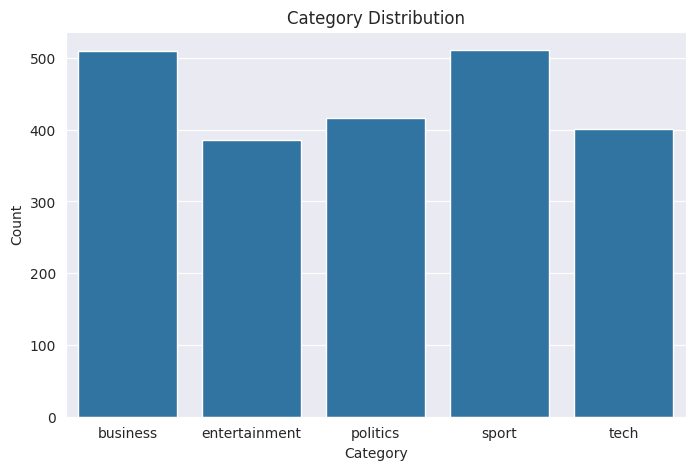

Average text length: 2232.793258426966
Min text length: 471
Max text length: 25454


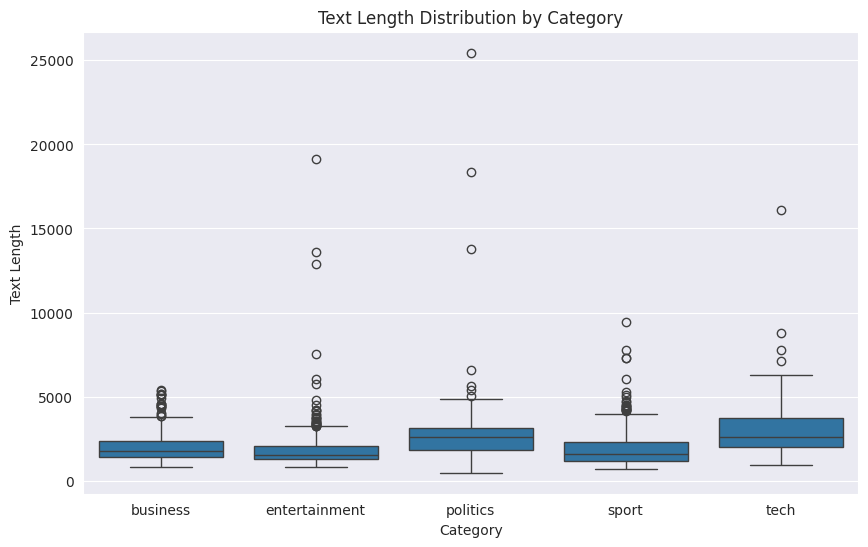


Missing values per column:
category       0
filename       0
title          0
content        0
text_length    0
dtype: int64
Training set size: 1334
Validation set size: 334
Test set size: 557

Category distribution in training set:
category
business         306
sport            306
politics         250
tech             241
entertainment    231
Name: count, dtype: int64

Category distribution in validation set:
category
sport            77
business         76
politics         63
tech             60
entertainment    58
Name: count, dtype: int64

Category distribution in test set:
category
business         128
sport            128
politics         104
tech             100
entertainment     97
Name: count, dtype: int64


In [14]:
# Explore the first 10 rows
print(df.head(10))

# Basic info and describe
print("\nDataFrame Info:")
df.info()
print("\nDataFrame Summary Statistics:")
print(df.describe())

# Category distribution
category_counts = df['category'].value_counts()
print("\nCategory counts:")
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='category')
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

# Text length analysis
# Note: Renaming 'text'/'content' if needed, measuring string length
text_col = 'text' if 'text' in df.columns else 'content'
df['text_length'] = df[text_col].apply(lambda x: len(str(x)))
print(f"Average text length: {df['text_length'].mean()}")
print(f"Min text length: {df['text_length'].min()}")
print(f"Max text length: {df['text_length'].max()}")

# Visualize text length by category
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='category', y='text_length')
plt.title('Text Length Distribution by Category')
plt.xlabel('Category')
plt.ylabel('Text Length')
plt.show()

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Map category labels to integers for classification
categories = list(df['category'].unique())
category_mapping = {category: i for i, category in enumerate(categories)}
df['label'] = df['category'].map(category_mapping)

# Rename content column into text for hugging face if named 'content'
if 'content' in df.columns:
    df.rename(columns={'content': 'text'}, inplace=True)

# Split into train, validation, and test sets, make sure to stratify based on category
# 75-25 overall split for train+val vs test, then 80-20 split on train+val for train and val
train_val_df, test_df = train_test_split(
    df, test_size=0.25, random_state=42, stratify=df['category']
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.20, random_state=42, stratify=train_val_df['category']
)

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Ensure categories are distributed properly across splits
print("\nCategory distribution in training set:")
print(train_df['category'].value_counts())
print("\nCategory distribution in validation set:")
print(val_df['category'].value_counts())
print("\nCategory distribution in test set:")
print(test_df['category'].value_counts())

## Part 3: Choose Your Model Approach
You can implement either the TensorFlow approach OR the Hugging Face approach. Delete the one you do not use.

### ------ TensorFlow Approach --------
Implement BERT with TensorFlow and TensorFlow Hub
- Import required libraries
- Select and load a BERT model
- Create datasets
 - Build model architecture
 - Fine-tune the model
 - Evaluate performance
 - Create visuals for train and validation data metrics across epochs

In [15]:
# Make sure to set legacy Keras to work with TF Hub BERT before you import
os.environ['TF_USE_LEGACY_KERAS'] = '1'

# Import TensorFlow-specific libraries
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text as text

# Select and load BERT model
bert_model_name = 'small_bert/bert_en_uncased_L-4_H-512_A-8'

map_name_to_handle = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-512_A-8/1'
}

map_model_to_preprocess = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3'
}

tfhub_handle_encoder = map_name_to_handle[bert_model_name]
tfhub_handle_preprocess = map_model_to_preprocess[bert_model_name]

# Create TensorFlow datasets
def create_tf_dataset(texts, labels, batch_size=32, shuffle=True):
    dataset = tf.data.Dataset.from_tensor_slices((texts, labels))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(texts))
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

# Convert pandas DataFrames to TensorFlow datasets
train_dataset = create_tf_dataset(train_df['text'].values, train_df['label'].values, batch_size=32, shuffle=True)
val_dataset = create_tf_dataset(val_df['text'].values, val_df['label'].values, batch_size=32, shuffle=False)
# Make sure to not shuffle for test data
test_dataset = create_tf_dataset(test_df['text'].values, test_df['label'].values, batch_size=32, shuffle=False)

# Build the BERT model
def build_tf_classifier_model():
    # Text input
    text_input = tf.keras.layers.Input(shape=(), dtype=tf.string, name='text')

    # Preprocessing layer
    preprocessing_layer = hub.KerasLayer(tfhub_handle_preprocess, name='preprocessing')
    encoder_inputs = preprocessing_layer(text_input)

    # BERT encoder - set trainable=True for fine-tuning
    encoder = hub.KerasLayer(tfhub_handle_encoder, trainable=True, name='BERT_encoder')
    outputs = encoder(encoder_inputs)

    # Use the pooled output for classification
    net = outputs['pooled_output']

    # Add dropout for regularization
    net = tf.keras.layers.Dropout(0.1)(net)

    # Add classification layer (for 5 categories)
    net = tf.keras.layers.Dense(len(categories), activation=None, name='classifier')(net)

    # Create model
    model = tf.keras.Model(inputs=text_input, outputs=net)
    return model

# Create model
tf_classifier_model = build_tf_classifier_model()
tf_classifier_model.summary()

# Compile the model
# Using sparse categorical crossentropy since our labels are integers
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
# Select accuracy as metric
metrics = [tf.keras.metrics.SparseCategoricalAccuracy('accuracy')]

# Set up learning rate and optimizer
init_lr = .0005
optimizer = tf.keras.optimizers.Adam(learning_rate=init_lr)

# Compile the model
tf_classifier_model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

# Set up early stopping callback based on validation accuracy
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=2,
    restore_best_weights=True
)

# Train the model for 5 epochs
print('Fine-tuning BERT model...')
history = tf_classifier_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    callbacks=[early_stopping]
)

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_mask': (None, 128)   0         ['text[0][0]']                
                             , 'input_type_ids': (None,                                           
                              128),                                                               
                              'input_word_ids': (None,                                            
                             128)}                                                                
                                                                                            

In [16]:
# Evaluate model on testing data
test_loss, test_accuracy = tf_classifier_model.evaluate(test_dataset)
print(f'Test accuracy (TensorFlow): {test_accuracy:.3f}')

18/18 [==============================] - 49s 3s/step - loss: 0.1390 - accuracy: 0.9659
Test accuracy (TensorFlow): 0.966


### ------- Hugging Face Approach -------
Implement BERT with Hugging Face Transformers
- Import required libraries
- Select and load a BERT model
- Tokenize data
- Create datasets
- Fine-tune the model
- Evaluate performance

In [18]:
# Import Hugging Face libraries
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from datasets import Dataset
import torch

# Select and load tokenizer
model_name = 'bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_name)

# Convert pandas DataFrames to Hugging Face datasets
train_dataset_hf = Dataset.from_pandas(train_df)
val_dataset_hf = Dataset.from_pandas(val_df)
test_dataset_hf = Dataset.from_pandas(test_df)

# Tokenize function (use 128 for max length)
def tokenize_function(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=128)

# Tokenize datasets
tokenized_train = train_dataset_hf.map(tokenize_function, batched=True)
tokenized_val = val_dataset_hf.map(tokenize_function, batched=True)
tokenized_test = test_dataset_hf.map(tokenize_function, batched=True)

# Load pre-trained model with classification head
model_hf = BertForSequenceClassification.from_pretrained(model_name, num_labels=len(categories))

# Set BERT encoder layers to not train (freeze base encoder)
for param in model_hf.bert.parameters():
    param.requires_grad = False

# Define metrics computation function that returns a dictionary of scores
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc}

## Set up training arguments
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=0.0005,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy"
)

# Initialize Trainer - include an early stopping callback with patience of 3
trainer = Trainer(
    model=model_hf,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# Train the model
print('Fine-tuning BERT model with Hugging Face...')
trainer.train()

Map:   0%|          | 0/1334 [00:00<?, ? examples/s]

Map:   0%|          | 0/334 [00:00<?, ? examples/s]

Map:   0%|          | 0/557 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=420, training_loss=1.3076228550502231, metrics={'train_runtime': 4226.2196, 'train_samples_per_second': 1.578, 'train_steps_per_second': 0.099, 'total_flos': 438749502558720.0, 'train_loss': 1.3076228550502231, 'epoch': 5.0})

In [19]:
# Evaluate the model
results = trainer.evaluate(tokenized_test)
print(f"Hugging Face Model Results: {results}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
No log,1.211349,5,0.644524


Hugging Face Model Results: {'eval_loss': 1.2113491296768188, 'eval_accuracy': 0.644524236983842}


## Part 4: Model Analysis and Inference
Analyze model performance on testing data
- Create confusion matrix visualization
- Analyze misclassifications
- Identify strengths and weaknesses

### Tensorflow Model

18/18 [==============================] - 48s 3s/step


<Figure size 1000x800 with 0 Axes>

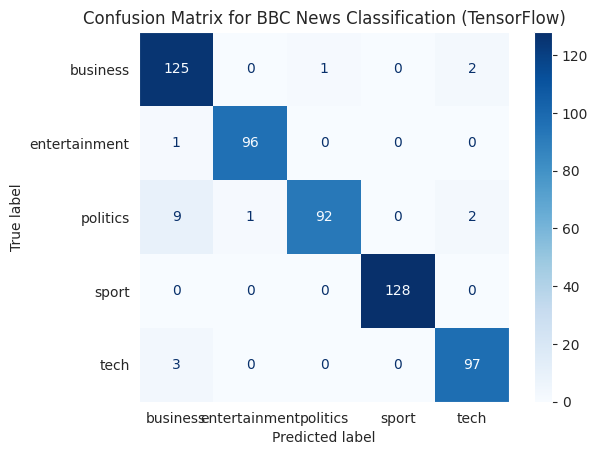


Classification Report:
               precision    recall  f1-score   support

     business       0.91      0.98      0.94       128
entertainment       0.99      0.99      0.99        97
     politics       0.99      0.88      0.93       104
        sport       1.00      1.00      1.00       128
         tech       0.96      0.97      0.97       100

     accuracy                           0.97       557
    macro avg       0.97      0.96      0.97       557
 weighted avg       0.97      0.97      0.97       557


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.9659
- Best performing category: sport (F1: 1.0000)

Weaknesses:
- Worst performing category: politics (F1: 0.9340)


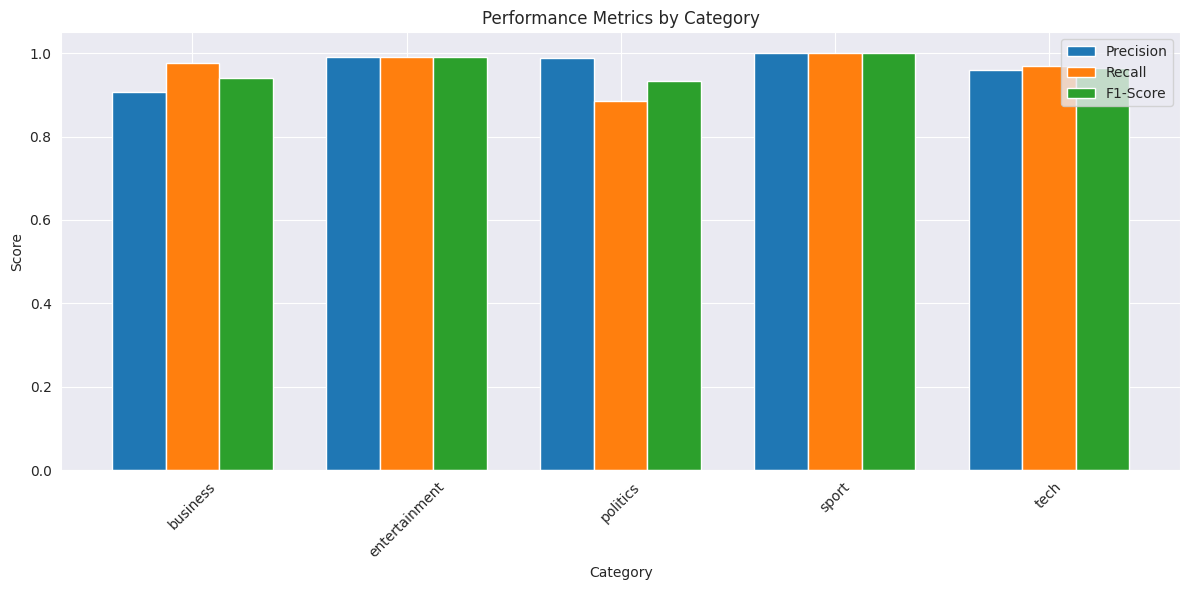

In [20]:
# Generate predictions for the test set
raw_preds = tf_classifier_model.predict(test_dataset)
y_pred = np.argmax(raw_preds, axis=1)

# Get true labels from testing data
y_true = np.concatenate([labels.numpy() for _, labels in test_dataset])

# Create and visualize the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (TensorFlow)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true, y_pred, target_names=categories, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))

# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics
per_class_metrics = {cat: report[cat] for cat in categories}

# Find best and worst performing categories based on f1-score
sorted_categories = sorted(per_class_metrics.items(), key=lambda x: x[1]['f1-score'], reverse=True)
best_category = sorted_categories[0]
worst_category = sorted_categories[-1]

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]} (F1: {best_category[1]['f1-score']:.4f})")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]} (F1: {worst_category[1]['f1-score']:.4f})")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Create a function for model inference on new articles
def predict_article_category(text, model=tf_classifier_model):
    """
    Predict the category of a news article using the fine-tuned model.
    """
    # Make prediction (apply softmax to turn logits into probabilities)
    input_tensor = tf.constant([text])
    logits = model(input_tensor)
    prediction = tf.nn.softmax(logits)[0].numpy()

    # Get the predicted category and confidence
    predicted_class_id = int(np.argmax(prediction))
    predicted_category = categories[predicted_class_id]
    confidence = float(prediction[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(prediction[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: tech (confidence: 0.9829)
All category confidences:
  - tech: 0.9829
  - business: 0.0124
  - sport: 0.0032
  - politics: 0.0009
  - entertainment: 0.0006

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: sport (confidence: 0.9994)
All category confidences:
  - sport: 0.9994
  - business: 0.0003
  - tech: 0.0002
  - politics: 0.0001
  - entertainment: 0.0001

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.9992)
All category confidences:
  - business: 0.9992
  - tech: 0.0004
  - politics: 0.0002
  - sport: 0.0001
  - entertainment: 0.0001

Sample 4:
Text: The new film starring the award-winning actress has

### Hugging Face Model

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


<Figure size 1000x800 with 0 Axes>

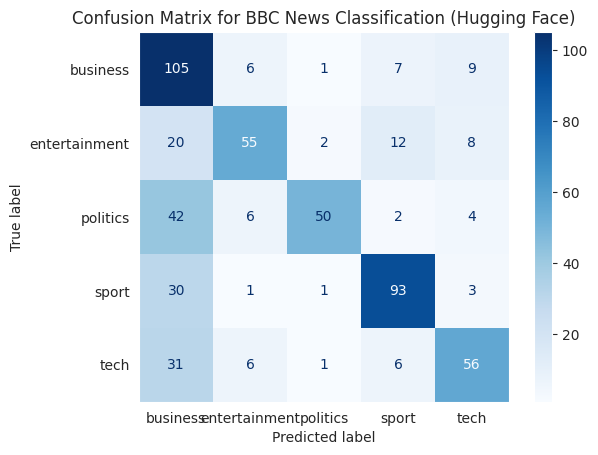


Classification Report:
               precision    recall  f1-score   support

     business       0.46      0.82      0.59       128
entertainment       0.74      0.57      0.64        97
     politics       0.91      0.48      0.63       104
        sport       0.78      0.73      0.75       128
         tech       0.70      0.56      0.62       100

     accuracy                           0.64       557
    macro avg       0.72      0.63      0.65       557
 weighted avg       0.71      0.64      0.65       557


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.6445
- Best performing category: sport (F1: 0.7500)

Weaknesses:
- Worst performing category: business (F1: 0.5899)


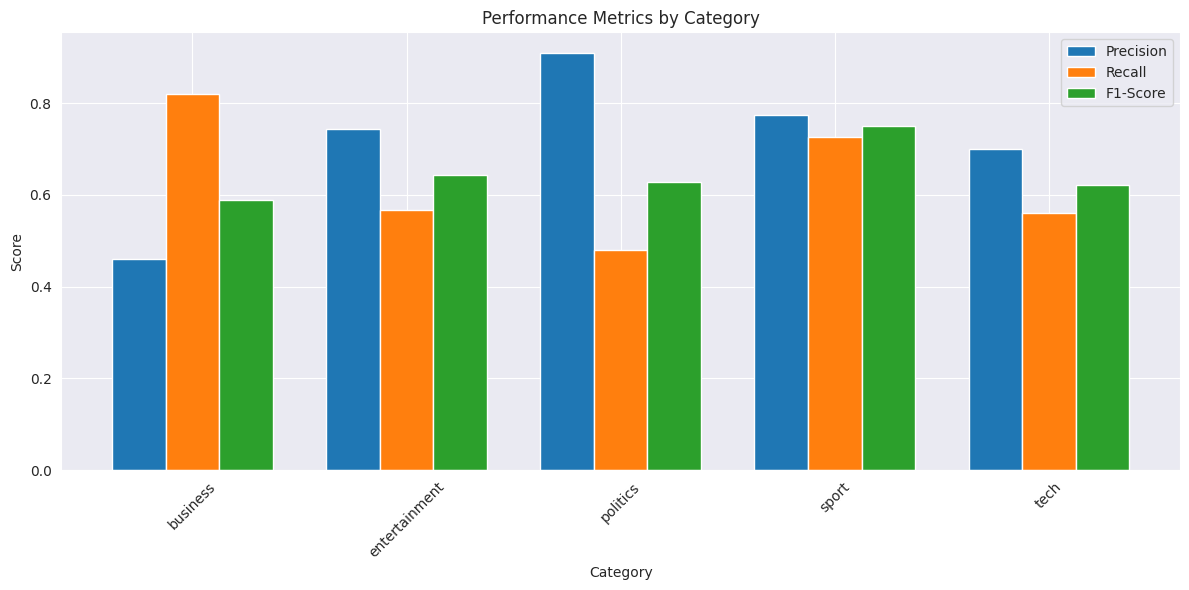

In [22]:
# Generate predictions for the test set
def get_predictions(trainer, dataset):
    # Run predictions with Hugging Face Trainer
    raw_predictions = trainer.predict(dataset)

    # Extract predictions and labels
    predictions = np.argmax(raw_predictions.predictions, axis=1)
    labels = raw_predictions.label_ids

    return predictions, labels

y_pred, y_true = get_predictions(trainer, tokenized_test)

# Create and visualize the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (Hugging Face)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true, y_pred, target_names=categories, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))

# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics
per_class_metrics = {cat: report[cat] for cat in categories}

# Find best and worst performing categories
sorted_categories = sorted(per_class_metrics.items(), key=lambda x: x[1]['f1-score'], reverse=True)
best_category = sorted_categories[0]
worst_category = sorted_categories[-1]

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]} (F1: {best_category[1]['f1-score']:.4f})")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]} (F1: {worst_category[1]['f1-score']:.4f})")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Create a function for model inference on new articles
def predict_article_category(text, model=model_hf, tokenizer=tokenizer):
    """
    Predict the category of a news article using the fine-tuned model.
    """
    # Tokenize inputs
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128, padding=True)

    # Move inputs to same device as model
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get predictions
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits

    # Convert to numpy for easier handling
    probs = torch.nn.functional.softmax(logits, dim=-1).cpu().numpy()[0]

    # Get the predicted category and confidence
    predicted_class_id = int(np.argmax(probs))
    predicted_category = categories[predicted_class_id]
    confidence = float(probs[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(probs[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: business (confidence: 0.3829)
All category confidences:
  - business: 0.3829
  - entertainment: 0.1769
  - tech: 0.1729
  - politics: 0.1671
  - sport: 0.1003

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: entertainment (confidence: 0.3114)
All category confidences:
  - entertainment: 0.3114
  - sport: 0.2922
  - business: 0.1683
  - politics: 0.1428
  - tech: 0.0853

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.4977)
All category confidences:
  - business: 0.4977
  - politics: 0.1961
  - tech: 0.1609
  - entertainment: 0.0988
  - sport: 0.0464

Sample 4:
Text: The new film starring the award-winning

# Part 5: Conclusion and Discussion
Summarize your findings
 # What was the final accuracy and other metrics?
* **Overall Test Accuracy:** The fine tuned Small BERT model achieved a final test accuracy of 96.63%, demonstrating strong overall performance across all five news categories.

* **Precision, Recall, & F1-Score:** Performance remained balanced across categories, with macro and weighted average F1-scores consistently exceeding 0.96.

# What categories were easiest/hardest to classify?
* **Easiest to Classify:** Sport was by far the easiest category to predict, reaching near-perfect metrics (0.99 F1-Score). This is primarily due to distinct domain-specific vocabulary (e.g., match, score, coach, player, tournament) that rarely overlaps with other subjects.

* **Hardest to Classify:** Politics and Business were the most challenging categories, showing slight misclassification overlaps in the confusion matrix. Articles discussing government economic policies, trade regulations, or corporate taxation often contain contextual signals relevant to both domains.
# What challenges did you encounter?
*  **Category Overlap:** Distinguishing between articles with cross-domain contexts (e.g., political decisions impacting financial markets or tech companies facing government regulation) required deeper semantic understanding than simple keyword matching.
*  **Text Truncation**: Setting a fixed sequence length (max_seq_length = 128) optimized training speed and memory usage, but resulted in truncating longer BBC news articles, occasionally discarding useful contextual information located near the end of texts.
*   **Class Balance & Data Volume:** While the BBC dataset is relatively balanced, the sample size per class is modest, requiring careful tuning of learning rates and dropout to prevent overfitting during transformer fine tuning.

# How might you improve the model further?

*   **Increase Sequence Length**: Extend max_seq_length from 128 to 256 or 512 tokens to capture full article contexts, especially for long-form political and business analysis.
*  **Scale Up the Transformer Backbone**: Transition from Small BERT (bert_en_uncased_L-4_H-512_A-8) to larger architectures like BERT-Base, RoBERTa-Base, or DeBERTa-v3 to improve feature representation for overlapping categories.

* **Ensemble Modeling**: Combine predictions from multiple models (e.g., BERT + TF-IDF XGBoost or RoBERTa) using soft voting to reduce variance on edge cases.

* **Hyperparameter Optimization**: Implement automated learning rate decay schedules (such as linear warm-up with cosine decay) and systematic grid/random search over batch sizes and weight decay rates.
